# Data Cleanup & Visualisation

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# Load datasets
train = pd.read_csv(os.path.join('data', 'fraudTrain.csv'))
test  = pd.read_csv(os.path.join('data', 'fraudTest.csv'))

train.head()

,Unnamed: 0.1,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [24]:
# Drop nulls and duplicates
train = train.dropna().drop_duplicates().reset_index(drop=True)
test  = test.dropna().drop_duplicates().reset_index(drop=True)

In [ ]:
# Dataset overview 
def overview(df, name):
    print(f'--- {name} Overview ---')
    print('Shape:', df.shape)
    print(f'Column types:\n{df.dtypes}')
    print(f'Unique values per column:\n{df.nunique()}')
    
    num = df.select_dtypes(include=[np.number])
    if not num.empty:
        print(f'Mean of numeric columns:\n{num.mean()}')
        
    print('-'*40)

overview(train, 'Train')
overview(test, 'Test')

--- Train Overview ---
Shape: (30000, 24)
Column types:
Unnamed: 0.1               int64
Unnamed: 0                 int64
trans_date_trans_time     object
cc_num                     int64
merchant                  object
category                  object
amt                      float64
first                     object
last                      object
gender                    object
street                    object
city                      object
state                     object
zip                        int64
lat                      float64
long                     float64
city_pop                   int64
job                       object
dob                       object
trans_num                 object
unix_time                  int64
merch_lat                float64
merch_long               float64
is_fraud                   int64
dtype: object
Unique values per column:
Unnamed: 0.1             30000
Unnamed: 0               30000
trans_date_trans_time    29657
cc_num             

In [26]:
# Haversine distance function
def distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

train['distance'] = distance(train['lat'], train['long'], train['merch_lat'], train['merch_long'])
test['distance']  = distance(test['lat'], test['long'], test['merch_lat'], test['merch_long'])

In [27]:
# Helper to compute fraud rates (≥10 transactions)
def fraud_rate(df, col):
    grp = df.groupby(col).agg(total=('is_fraud','size'), fraud=('is_fraud','sum')).reset_index()
    grp = grp[grp['total'] >= 10].copy()
    grp['fraud_pct'] = grp['fraud'] / grp['total'] * 100
    return grp.sort_values('fraud_pct', ascending=False)

global_fraud_pct = train['is_fraud'].mean() * 100
print(f'Global fraud percentage: {global_fraud_pct:.2f}%')

Global fraud percentage: 0.96%


C:\Users\hp\AppData\Local\Temp\ipykernel_23300\2227025703.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(top_15_merchants['merchant'].astype(str), rotation=45, ha='right')


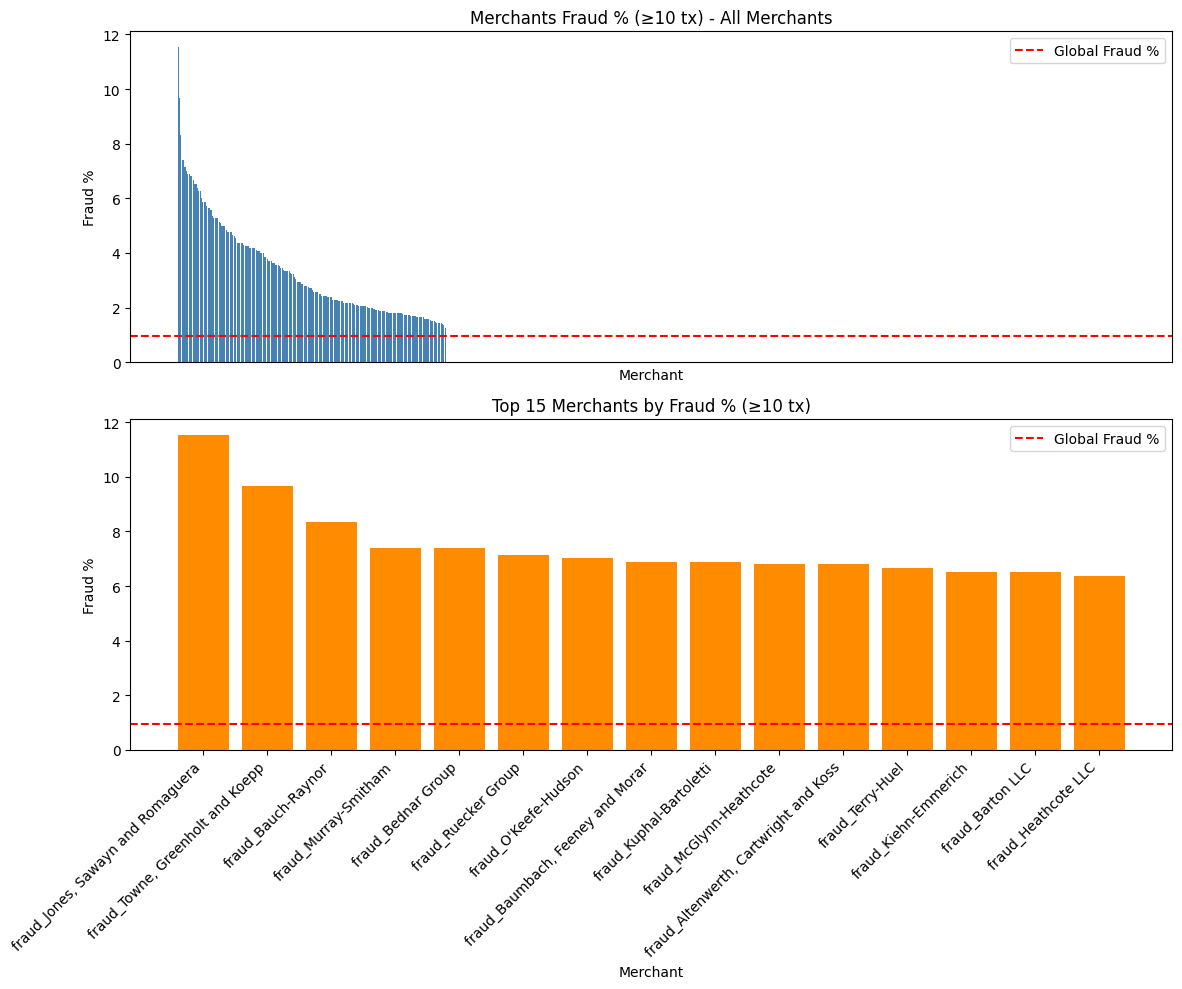

In [28]:
# 1. Merchants fraud rate (≥10 transactions)
merchant_rates = fraud_rate(train, 'merchant')

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12, 10))

ax.bar(merchant_rates['merchant'].astype(str), merchant_rates['fraud_pct'], color='steelblue')
ax.set_title('Merchants Fraud % (≥10 tx) - All Merchants')
ax.set_xlabel('Merchant')
ax.set_ylabel('Fraud %')

ax.set_xticks([]) 

ax.axhline(global_fraud_pct, color='red', linestyle='--', label='Global Fraud %')
ax.legend()

top_15_merchants = merchant_rates.nlargest(15, 'fraud_pct')

ax2.bar(top_15_merchants['merchant'].astype(str), top_15_merchants['fraud_pct'], color='darkorange')
ax2.set_title('Top 15 Merchants by Fraud % (≥10 tx)')
ax2.set_xlabel('Merchant')
ax2.set_ylabel('Fraud %')

ax2.set_xticklabels(top_15_merchants['merchant'].astype(str), rotation=45, ha='right')

ax2.axhline(global_fraud_pct, color='red', linestyle='--', label='Global Fraud %')
ax2.legend()

plt.tight_layout()
plt.savefig('figures/merchant_fraud_rate.png', dpi=150)
plt.show()
plt.close()

C:\Users\hp\AppData\Local\Temp\ipykernel_23300\685733476.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(top_15_jobs['job'].astype(str), rotation=45, ha='right')


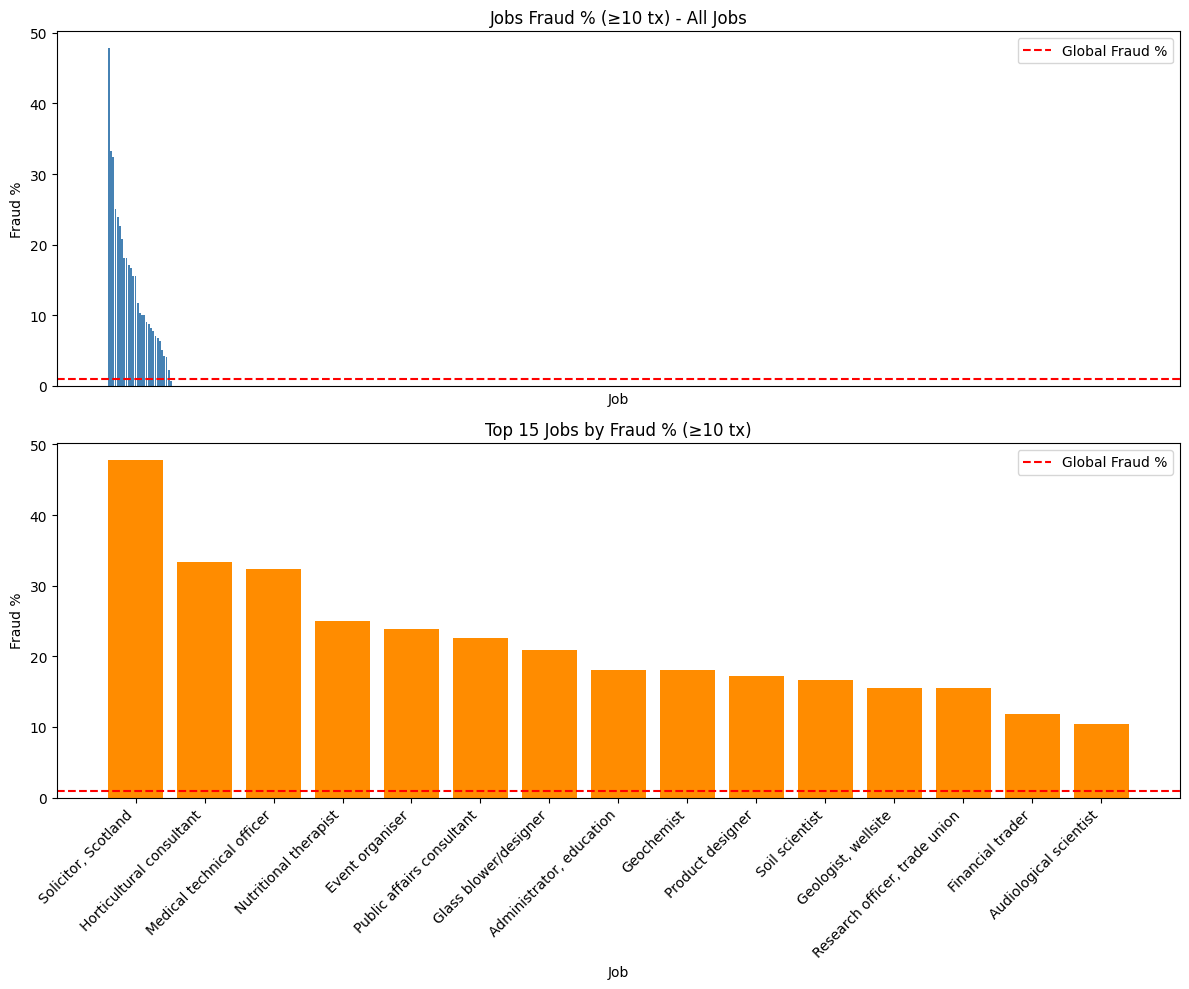

In [29]:
# 2. Jobs fraud rate (≥10 transactions)
job_rates = fraud_rate(train, 'job')

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12, 10))

ax.bar(job_rates['job'].astype(str), job_rates['fraud_pct'], color='steelblue')
ax.set_title('Jobs Fraud % (≥10 tx) - All Jobs')
ax.set_xlabel('Job')
ax.set_ylabel('Fraud %')

ax.set_xticks([])

ax.axhline(global_fraud_pct, color='red', linestyle='--', label='Global Fraud %')
ax.legend()

top_15_jobs = job_rates.nlargest(15, 'fraud_pct')

ax2.bar(top_15_jobs['job'].astype(str), top_15_jobs['fraud_pct'], color='darkorange')
ax2.set_title('Top 15 Jobs by Fraud % (≥10 tx)')
ax2.set_xlabel('Job')
ax2.set_ylabel('Fraud %')

ax2.set_xticklabels(top_15_jobs['job'].astype(str), rotation=45, ha='right')

ax2.axhline(global_fraud_pct, color='red', linestyle='--', label='Global Fraud %')
ax2.legend()

plt.tight_layout()
plt.savefig('figures/job_fraud_rate.png', dpi=150)
plt.show()
plt.close()

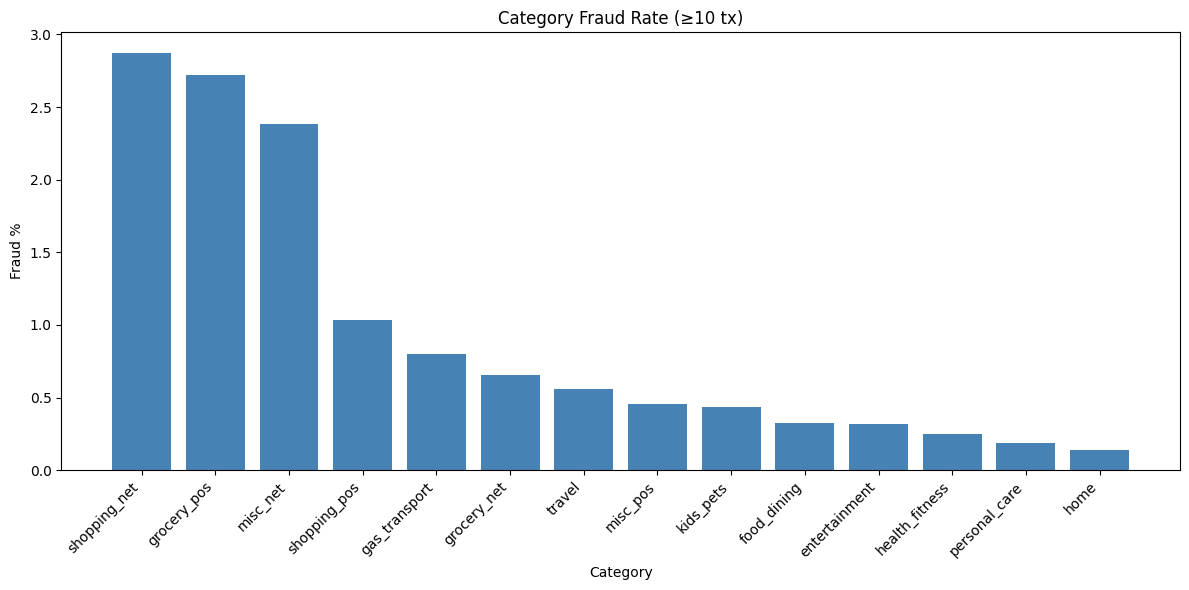

In [30]:
# 3. Category vs fraud rate
cat_rates = fraud_rate(train, 'category')
fig, ax = plt.subplots(figsize=(12,6))
ax.bar(cat_rates['category'].astype(str), cat_rates['fraud_pct'], color='steelblue')
ax.set_title('Category Fraud Rate (≥10 tx)')
ax.set_xlabel('Category')
ax.set_ylabel('Fraud %')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('figures/category_fraud_rate.png')
plt.show()
plt.close()

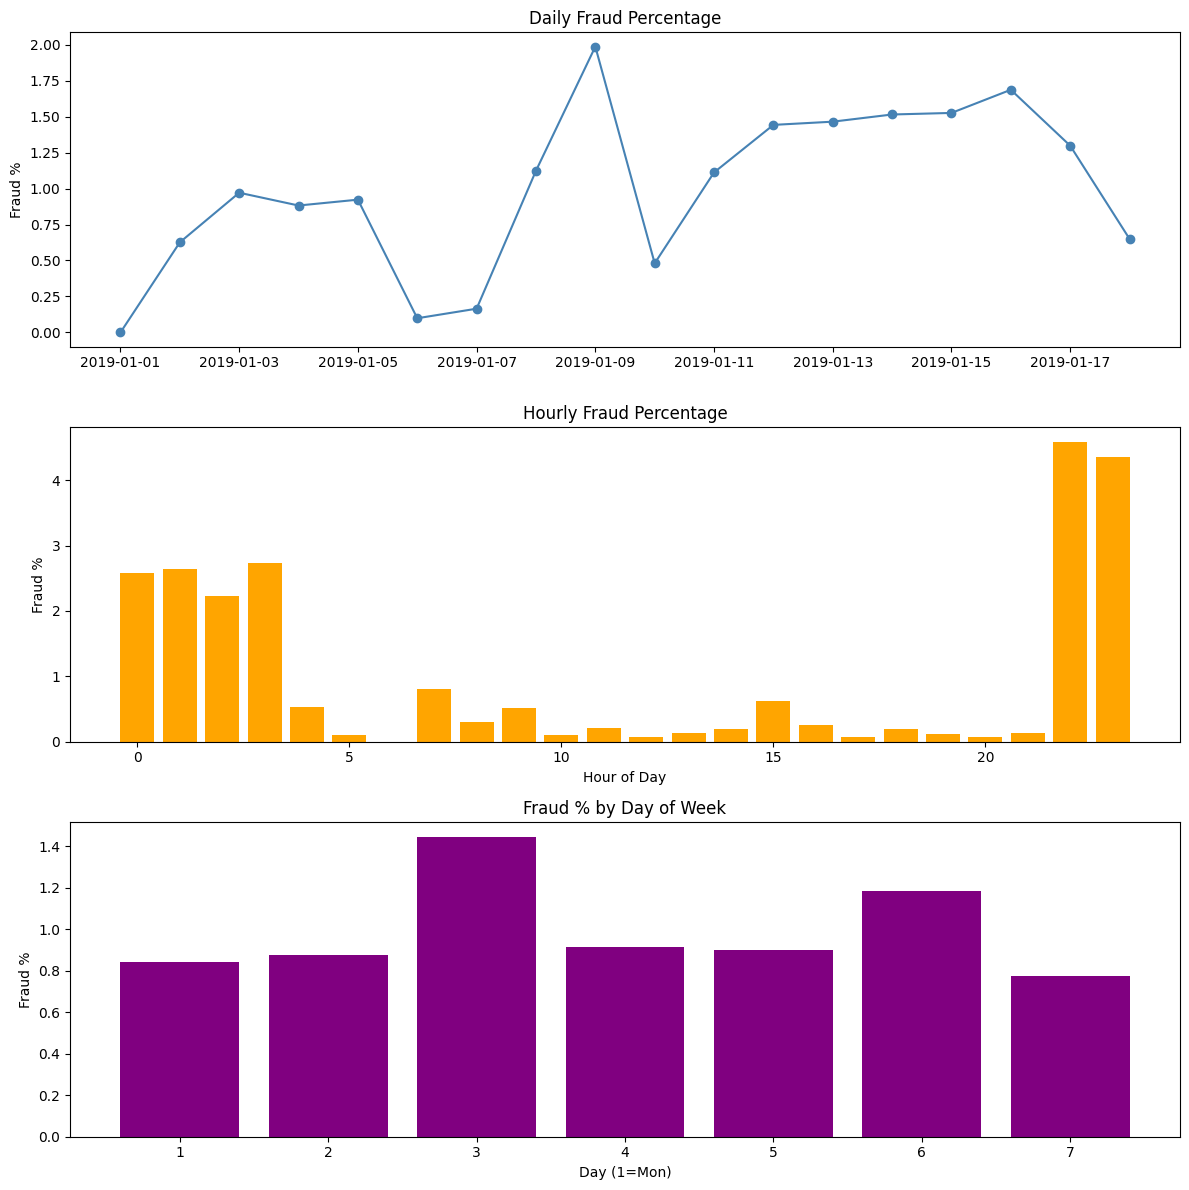

In [31]:
# # 4. Fraud over time: daily, hourly, day of week
train['dt'] = pd.to_datetime(train['trans_date_trans_time'])

fig, (ax, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12))


daily = train.set_index('dt').resample('D').agg(total=('is_fraud', 'size'), fraud=('is_fraud', 'sum')).reset_index()
daily['fraud_pct'] = daily['fraud'] / daily['total'] * 100

ax.plot(daily['dt'], daily['fraud_pct'], marker='o', color='steelblue')
ax.set_title('Daily Fraud Percentage')
ax.set_ylabel('Fraud %')

train['hour'] = train['dt'].dt.hour
hourly = train.groupby('hour').agg(total=('is_fraud', 'size'), fraud=('is_fraud', 'sum')).reset_index()
hourly['fraud_pct'] = hourly['fraud'] / hourly['total'] * 100

ax2.bar(hourly['hour'], hourly['fraud_pct'], color='orange')
ax2.set_title('Hourly Fraud Percentage')
ax2.set_xlabel('Hour of Day')
ax2.set_ylabel('Fraud %')

train['dow'] = train['dt'].dt.dayofweek + 1
dow = train.groupby('dow').agg(total=('is_fraud', 'size'), fraud=('is_fraud', 'sum')).reset_index()
dow['fraud_pct'] = dow['fraud'] / dow['total'] * 100

ax3.bar(dow['dow'], dow['fraud_pct'], color='purple')
ax3.set_title('Fraud % by Day of Week')
ax3.set_xlabel('Day (1=Mon)')
ax3.set_ylabel('Fraud %')

plt.tight_layout()
plt.savefig('figures/fraud_over_time_combined.png', dpi=150)
plt.show()
plt.close()

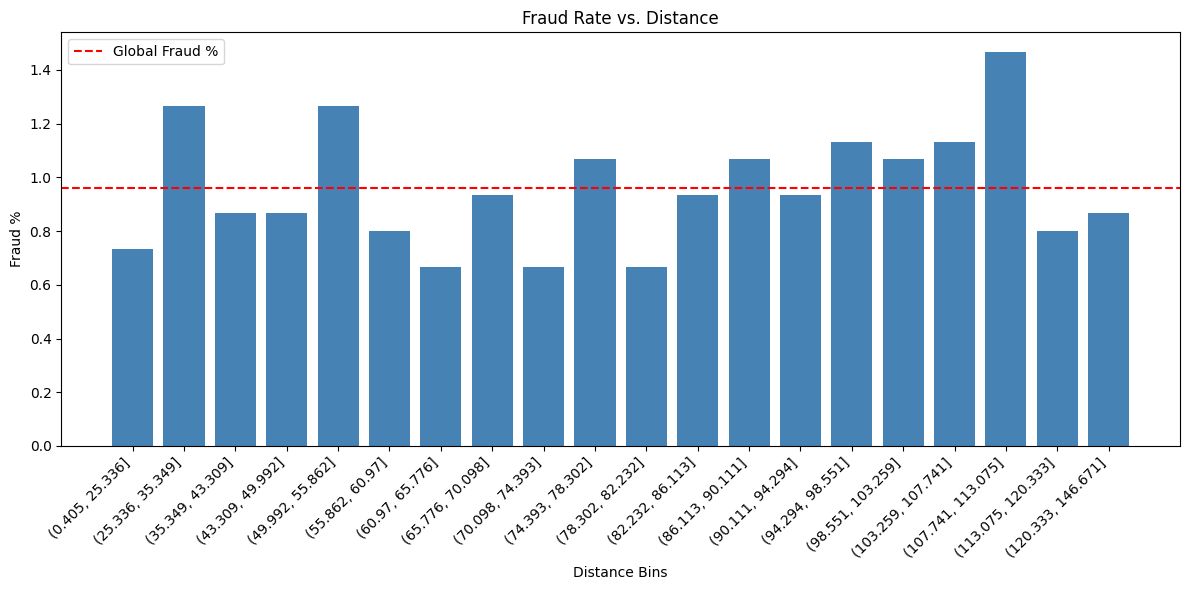

In [32]:
# 5. Fraud rate vs Distance
train['distance_bin'] = pd.qcut(train['distance'], q=20, duplicates='drop')

dist_rates = train.groupby('distance_bin', observed=False).agg(
    total=('is_fraud', 'size'), 
    fraud=('is_fraud', 'sum')
).reset_index()

dist_rates['fraud_pct'] = dist_rates['fraud'] / dist_rates['total'] * 100
dist_rates['distance_bin_str'] = dist_rates['distance_bin'].astype(str)

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(dist_rates['distance_bin_str'], dist_rates['fraud_pct'], color='steelblue')

ax.set_title('Fraud Rate vs. Distance')
ax.set_xlabel('Distance Bins')
ax.set_ylabel('Fraud %')
plt.xticks(rotation=45, ha='right')

if 'global_fraud_pct' in locals():
    ax.axhline(global_fraud_pct, color='red', linestyle='--', label='Global Fraud %')
    ax.legend()

plt.tight_layout()
plt.savefig('figures/fraud_rate_vs_distance.png', dpi=150)
plt.show()
plt.close()

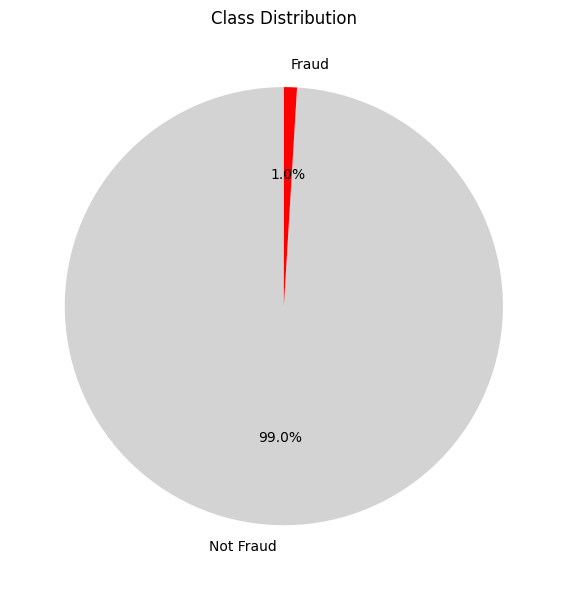

In [33]:
# 7. Overall class distribution (pie chart)
counts = train['is_fraud'].value_counts().sort_index()
labels = ['Not Fraud', 'Fraud']
fig, ax = plt.subplots(figsize=(6,6))
ax.pie(counts, labels=labels, autopct='%1.1f%%', startangle=90, colors=['lightgrey','red'])
ax.set_title('Class Distribution')
plt.tight_layout()
plt.savefig('figures/class_distribution.png')
plt.show()
plt.close()

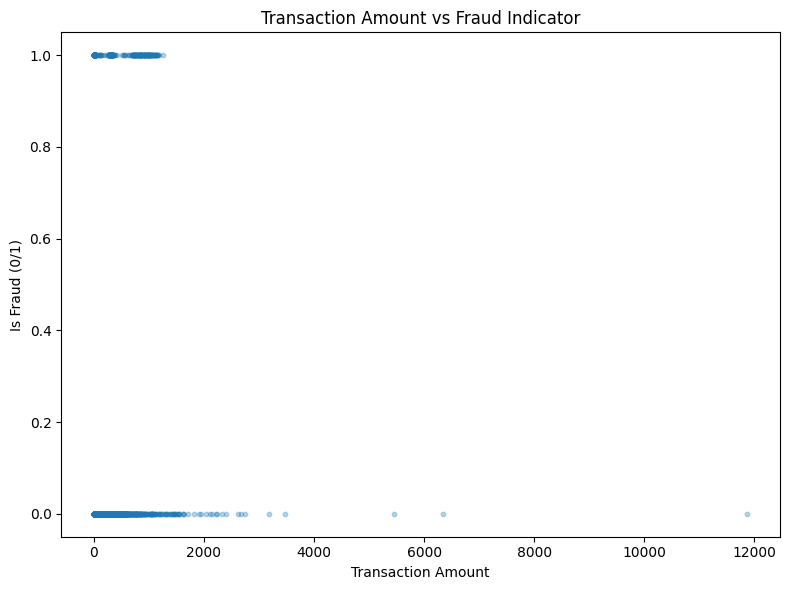

In [34]:
# 8. Transaction amount vs fraud (scatter)
fig, ax = plt.subplots(figsize=(8,6))
ax.scatter(train['amt'], train['is_fraud'], alpha=0.3, s=10)
ax.set_title('Transaction Amount vs Fraud Indicator')
ax.set_xlabel('Transaction Amount')
ax.set_ylabel('Is Fraud (0/1)')
plt.tight_layout()
plt.savefig('figures/amount_vs_fraud_scatter.png')
plt.show()
plt.close()

In [35]:
# Encoding & feature engineering

# Make sure datetime is converted and features are extracted 
for df in [train, test]:
    df['dt'] = pd.to_datetime(df['trans_date_trans_time'])
    df['hour'] = df['dt'].dt.hour
    df['dow'] = df['dt'].dt.dayofweek + 1

# One‑hot encode gender
train = pd.get_dummies(train, columns=['gender'], dtype=float)
test  = pd.get_dummies(test,  columns=['gender'], dtype=float)

# Replace DOB with age (already computed) – drop original DOB column
train = train.drop(columns=['dob'], errors='ignore')
test  = test.drop(columns=['dob'], errors='ignore')

#Drop columns not needed
cols_to_drop = [
    'first', 'last', 'Unnamed: 0', 'Unnamed: 0.1', 'city', 'state', 'zip', 
    'cc_num', 'category', 'lat', 'long', 'merch_lat', 'merch_long', 
    'trans_date_trans_time', 'dt', 'unix_time', 'street', 'trans_num', 'distance_bin'
]
drop_extra = [c for c in cols_to_drop if c in train.columns]
train = train.drop(columns=drop_extra)
test = test.drop(columns=drop_extra, errors='ignore')

# Replace trans_date_trans_time with recency score (day of week 1‑7) – already have 'day_of_week'
train = train.drop(columns=['trans_date_trans_time'], errors='ignore')
test  = test.drop(columns=['trans_date_trans_time'], errors='ignore')

def reorder(df):
    cols = ['is_fraud'] + [c for c in df.columns if c != 'is_fraud']
    return df[cols]
train = reorder(train)
test  = reorder(test)

In [36]:
# Encode merchant & job with fraud rates (≥10 transactions)
overall_fraud = train['is_fraud'].mean()

# Merchant rates
merch_stats = train.groupby('merchant')['is_fraud'].agg(['mean','size'])
merch_rate = merch_stats['mean'].where(merch_stats['size'] >= 10, other=overall_fraud)
merch_rate.name = 'merchant_fraud_rate'
merch_rate.to_csv('data/merchant_fraud_rate.csv', header=True)
train['merchant_fraud_rate'] = train['merchant'].map(merch_rate).fillna(overall_fraud)
test['merchant_fraud_rate']  = test['merchant'].map(merch_rate).fillna(overall_fraud)

# Job rates
job_stats = train.groupby('job')['is_fraud'].agg(['mean','size'])
job_rate = job_stats['mean'].where(job_stats['size'] >= 10, other=overall_fraud)
job_rate.name = 'job_fraud_rate'
job_rate.to_csv('data/job_fraud_rate.csv', header=True)
train['job_fraud_rate'] = train['job'].map(job_rate).fillna(overall_fraud)
test['job_fraud_rate']  = test['job'].map(job_rate).fillna(overall_fraud)

# Drop original categorical columns
train = train.drop(columns=['merchant','job'], errors='ignore')
test  = test.drop(columns=['merchant','job'], errors='ignore')

In [37]:
# Dataset overview (printed)
def overview(df, name):
    print(f'--- {name} Overview ---')
    print('Shape:', df.shape)
    print(f'Column types:\n{df.dtypes}')
    print(f'Unique values per column:\n{df.nunique()}')
    
    num = df.select_dtypes(include=[np.number])
    if not num.empty:
        print(f'Mean of numeric columns:\n{num.mean()}')
        
    print('-'*40)

overview(train, 'Train')
overview(test, 'Test')

--- Train Overview ---
Shape: (30000, 10)
Column types:
is_fraud                 int64
amt                    float64
city_pop                 int64
distance               float64
hour                     int32
dow                      int32
gender_F               float64
gender_M               float64
merchant_fraud_rate    float64
job_fraud_rate         float64
dtype: object
Unique values per column:
is_fraud                   2
amt                    12929
city_pop                 822
distance               30000
hour                      24
dow                        7
gender_F                   2
gender_M                   2
merchant_fraud_rate       88
job_fraud_rate            30
dtype: int64
Mean of numeric columns:
is_fraud                   0.009600
amt                       71.947015
city_pop               88927.903967
distance                  76.368240
hour                      12.770900
dow                        3.650167
gender_F                   0.544200
gender_M      

In [38]:
train.head()

,is_fraud,amt,city_pop,distance,hour,dow,gender_F,gender_M,merchant_fraud_rate,job_fraud_rate
0,0,4.97,3495,78.597568,0,2,1.0,0.0,0.0,0.0
1,0,107.23,149,30.212176,0,2,1.0,0.0,0.0,0.0
2,0,220.11,4154,108.206083,0,2,0.0,1.0,0.0,0.0
3,0,45.00,1939,95.673231,0,2,0.0,1.0,0.0,0.0
4,0,41.96,99,77.556744,0,2,0.0,1.0,0.0,0.0


In [39]:
# Standardise numeric features (except is_fraud and gender dummies)
gender_cols = [c for c in train.columns if c.startswith('gender_')]
numeric_cols = [c for c in train.columns if c not in gender_cols + ['is_fraud']]
means = train[numeric_cols].mean()
stds = train[numeric_cols].std().replace(0,1)
train[numeric_cols] = (train[numeric_cols] - means) / stds
test[numeric_cols] = (test[numeric_cols] - means) / stds

In [40]:
# Save final encoded datasets
train.to_csv('data/data_encoded_train.csv', index=False)
test.to_csv('data/data_encoded_test.csv', index=False)

In [ ]:
# 1. Load Original Encoded Train Data
X = train.drop(columns=['is_fraud']).values
y = train['is_fraud'].values
feature_cols = [c for c in train.columns if c != 'is_fraud']

classes, counts = np.unique(y, return_counts=True)
minority_class = classes[np.argmin(counts)]
majority_class = classes[np.argmax(counts)]

X_min = X[y == minority_class]
X_maj = X[y == majority_class]
n_min = len(X_min)
n_maj = len(X_maj)
n_samples_to_generate = n_maj - n_min


# 2. Random Over-Sampler
random_indices = np.random.choice(n_min, size=n_samples_to_generate, replace=True)
X_syn_rand = X_min[random_indices]
X_rand = np.vstack([X, X_syn_rand])
y_rand = np.hstack([y, np.full(n_samples_to_generate, minority_class)])

train_rand = pd.DataFrame(X_rand, columns=feature_cols)
train_rand.insert(0, 'is_fraud', y_rand)
# Cut down to 30,000 rows
train_rand = train_rand.sample(n=30000, random_state=42)
train_rand.to_csv('data/train_random_oversample.csv', index=False)


# 3. SMOTE
synthetic_smote = []
if n_samples_to_generate > 0:
    for _ in range(n_samples_to_generate):
        idx = np.random.randint(0, n_min)
        sample = X_min[idx]
        dists = np.linalg.norm(X_min - sample, axis=1)
        dists[idx] = np.inf
        k = min(5, n_min - 1)
        nn_indices = np.argsort(dists)[:k]
        neighbor = X_min[nn_indices[np.random.randint(0, k)]]
        synthetic_smote.append(sample + np.random.random() * (neighbor - sample))

synthetic_smote = np.array(synthetic_smote)
X_smote = np.vstack([X, synthetic_smote]) if len(synthetic_smote) > 0 else X
y_smote = np.hstack([y, np.full(len(synthetic_smote), minority_class)]) if len(synthetic_smote) > 0 else y

train_smote = pd.DataFrame(X_smote, columns=feature_cols)
train_smote.insert(0, 'is_fraud', y_smote)
# Cut down to 30,000 rows
train_smote = train_smote.sample(n=30000, random_state=42)
train_smote.to_csv('data/train_smote.csv', index=False)


# 4. SMOTE + Tomek Links
tomek_remove = []
for i in range(len(X_smote)):
    dists = np.linalg.norm(X_smote - X_smote[i], axis=1)
    dists[i] = np.inf
    nn_idx = np.argmin(dists)
    if y_smote[i] != y_smote[nn_idx]:
        dists_nn = np.linalg.norm(X_smote - X_smote[nn_idx], axis=1)
        dists_nn[nn_idx] = np.inf
        if np.argmin(dists_nn) == i and y_smote[i] == majority_class:
            tomek_remove.append(i)

mask = np.ones(len(X_smote), dtype=bool)
mask[tomek_remove] = False

train_tomek = pd.DataFrame(X_smote[mask], columns=feature_cols)
train_tomek.insert(0, 'is_fraud', y_smote[mask])
# Cut down to 30,000 rows
train_tomek = train_tomek.sample(n=30000, random_state=42)
train_tomek.to_csv('data/train_smote_tomek.csv', index=False)


# 5. Comparison Bar Plot of Class Splits
datasets = {
    'Original': train['is_fraud'],
    'Random Over-Sample': train_rand['is_fraud'],
    'SMOTE': train_smote['is_fraud'],
    'SMOTE + Tomek': train_tomek['is_fraud']
}

fig, ax = plt.subplots(figsize=(10, 6))
labels = list(datasets.keys())
zeros = [(ds == 0).sum() for ds in datasets.values()]
ones = [(ds == 1).sum() for ds in datasets.values()]

x = np.arange(len(labels))
width = 0.35

ax.bar(x - width/2, zeros, width, label='Class 0 (Non-Fraud)', color='steelblue')
ax.bar(x + width/2, ones, width, label='Class 1 (Fraud)', color='darkorange')

ax.set_title('Class Distribution Comparison Across Resampled Datasets (30k rows each)')
ax.set_xlabel('Dataset')
ax.set_ylabel('Sample Count')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.tight_layout()
plt.savefig('figures/class_distribution_comparison.png', dpi=150)
plt.show()
plt.close()

KeyboardInterrupt: 